# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Rafa Rizki Aira Swala | 5054251017 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
pd.set_option("display.max_columns", None)

print("Library berhasil diimport.")

Library berhasil diimport.


In [136]:
import matplotlib as mpl

def get_cmap(name, n=None):
    """Wrapper kompatibel untuk plt.cm.get_cmap di Matplotlib baru."""
    cmap = mpl.colormaps[name]
    if n is not None:
        return cmap.resampled(n)
    return cmap

In [137]:
file_path = "Mall_Customers.csv"

try:
    df = pd.read_csv(file_path)
    print(f"File '{file_path}' berhasil dimuat.")
except FileNotFoundError:
    print(f"ERROR: File '{file_path}' tidak ditemukan.")
    print("Pastikan Mall_Customers.csv ada di folder yang sama dengan notebook ini.")
    raise

print("\n5 Baris Pertama")
display(df.head())

print("\nUkuran Dataset (baris, kolom)")
print(df.shape)

print("\nTipe Data")
print(df.dtypes)

print("\nStatistik Deskriptif")
display(df.describe())

print("\nJumlah Missing Value per Kolom")
print(df.isnull().sum())

print("\nJumlah Baris Duplikat")
print(df.duplicated().sum())

File 'Mall_Customers.csv' berhasil dimuat.

5 Baris Pertama


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Ukuran Dataset (baris, kolom)
(200, 5)

Tipe Data
CustomerID                int64
Gender                      str
Age                       int64
Annual Income (k$)        int64
Spending Score (1-100)    int64
dtype: object

Statistik Deskriptif


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000



Jumlah Missing Value per Kolom
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah Baris Duplikat
0


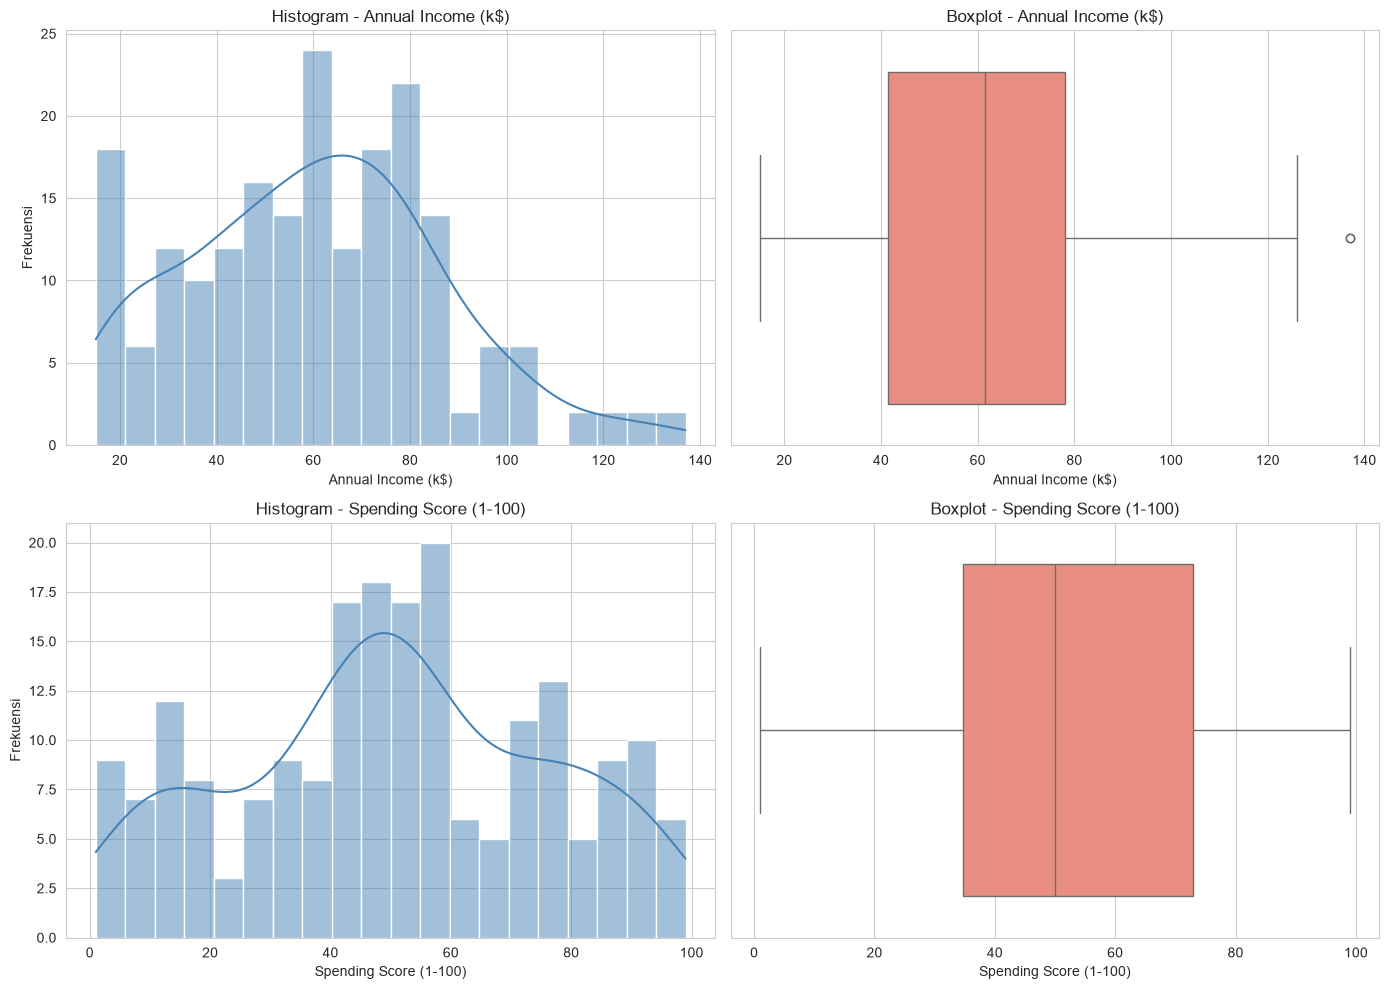

Ringkasan Statistik

Annual Income (k$):
  Min    : 15
  Q1     : 41.5
  Median : 61.5
  Q3     : 78.0
  Max    : 137
  Skew   : 0.322

Spending Score (1-100):
  Min    : 1
  Q1     : 34.8
  Median : 50.0
  Q3     : 73.0
  Max    : 99
  Skew   : -0.047


In [138]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for i, col in enumerate(features):
    sns.histplot(df[col], bins=20, kde=True, ax=axes[i, 0], color="steelblue")
    axes[i, 0].set_title(f"Histogram - {col}")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frekuensi")

    sns.boxplot(x=df[col], ax=axes[i, 1], color="salmon")
    axes[i, 1].set_title(f"Boxplot - {col}")
    axes[i, 1].set_xlabel(col)

plt.tight_layout()
plt.show()

print("Ringkasan Statistik")
for col in features:
    print(f"\n{col}:")
    print(f"  Min    : {df[col].min()}")
    print(f"  Q1     : {df[col].quantile(0.25):.1f}")
    print(f"  Median : {df[col].median():.1f}")
    print(f"  Q3     : {df[col].quantile(0.75):.1f}")
    print(f"  Max    : {df[col].max()}")
    print(f"  Skew   : {df[col].skew():.3f}")

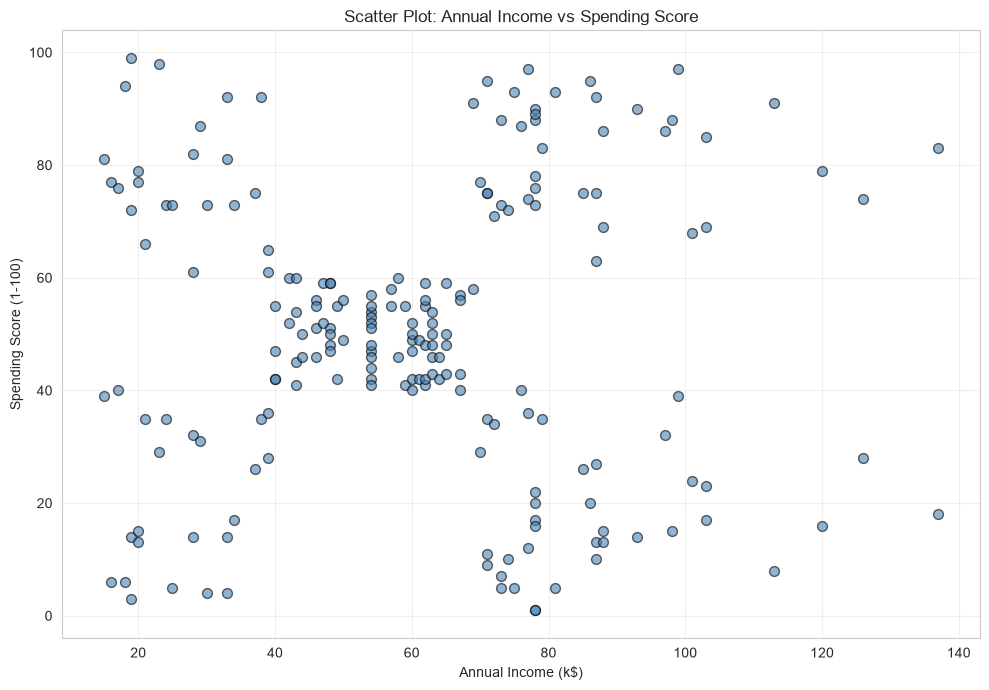

In [139]:
plt.figure(figsize=(10, 7))
plt.scatter(
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    alpha=0.6,
    edgecolors="k",
    s=50,
    color="steelblue",
)
plt.title("Scatter Plot: Annual Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
    Tidak ada missing value dan tidak ada baris duplikat.

- Bagaimana rentang pendapatan dan spending score?
    Annual Income (k$): rentang 15 sampai 137, median 61.5, IQR 41.5–78.0, skew 0.322 (sedikit miring kanan, tapi masih dianggap cukup simetris).

    Spending Score (1-100): rentang 1 sampai 99, median 50.0, IQR 34.8–73.0, skew -0.047 (hampir simetris sempurna).

- Apakah kedua fitur tampak memiliki kelompok yang terpisah?
    Income rendah (sekitar 15–40) dengan spending rendah (sekitar 1–20) dan spending tinggi (sekitar 70–100).

    Income menengah (sekitar 40–60) dengan spending menengah (sekitar 40–60), membentuk gumpalan padat.


# 2. Preprocessing

In [140]:
# Cek dan tangani missing value serta baris duplikat
print("Missing value sebelum handling:")
print(df.isnull().sum())

print("\nBaris duplikat sebelum handling:")
print(df.duplicated().sum())

# Tangani jika ada (di dataset ini seharusnya tidak ada)
df = df.dropna().drop_duplicates().reset_index(drop=True)

print("\nSetelah handling:")
print(f"Jumlah missing value : {df.isnull().sum().sum()}")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")
print(f"Ukuran dataset       : {df.shape}")

# Pilih dua fitur numerik untuk clustering
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features].copy()

print("\n5 Baris Pertama X")
display(X.head())

print("\nUkuran X")
print(X.shape)

Missing value sebelum handling:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Baris duplikat sebelum handling:
0

Setelah handling:
Jumlah missing value : 0
Jumlah baris duplikat: 0
Ukuran dataset       : (200, 5)

5 Baris Pertama X


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40



Ukuran X
(200, 2)


In [141]:
# Lakukan standardisasi
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X)

# Kembalikan ke DataFrame agar nama kolom tetap terlihat
X_scaled = pd.DataFrame(X_scaled_array, columns=features)

print("5 Baris Pertama X_scaled")
display(X_scaled.head())

print("\nStatistik Deskriptif X_scaled")
display(X_scaled.describe())

print("\nRata-rata per kolom (harus mendekati 0)")
print(X_scaled.mean().round(6))

print("\nStandar deviasi per kolom (harus mendekati 1)")
print(X_scaled.std(ddof=0).round(6))

5 Baris Pertama X_scaled


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980



Statistik Deskriptif X_scaled


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00



Rata-rata per kolom (harus mendekati 0)
Annual Income (k$)       -0.0
Spending Score (1-100)   -0.0
dtype: float64

Standar deviasi per kolom (harus mendekati 1)
Annual Income (k$)        1.0
Spending Score (1-100)    1.0
dtype: float64


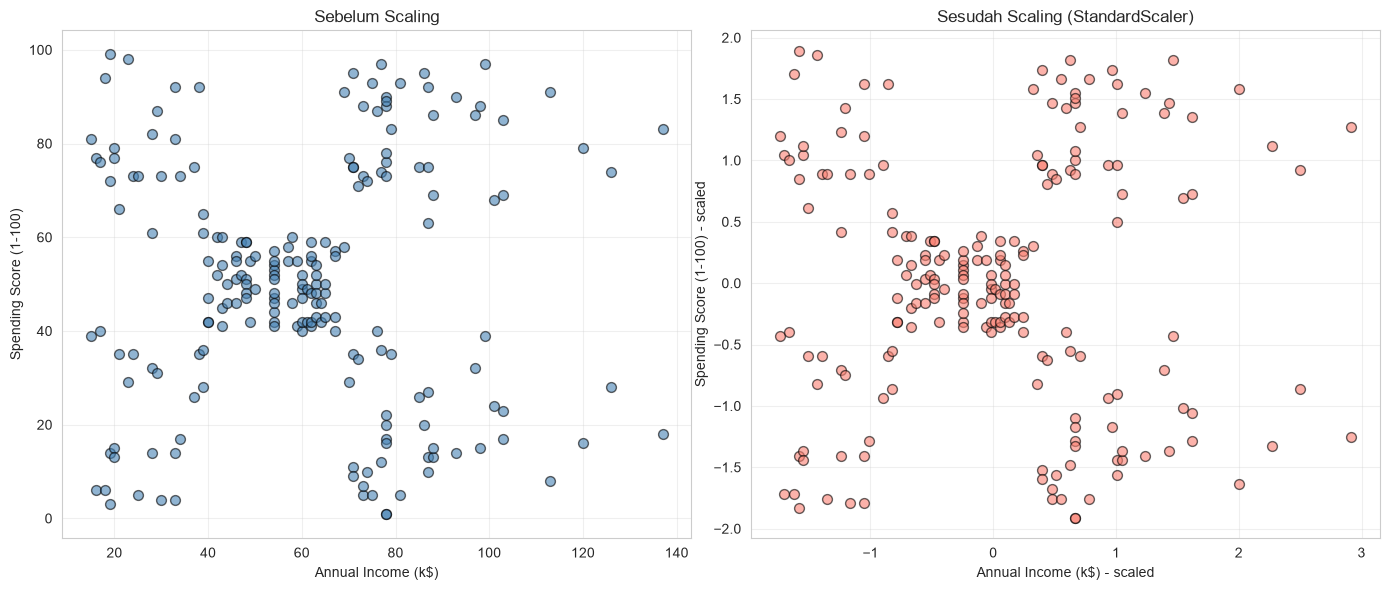

In [142]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sebelum scaling
axes[0].scatter(
    X["Annual Income (k$)"],
    X["Spending Score (1-100)"],
    alpha=0.6, edgecolors="k", s=50, color="steelblue",
)
axes[0].set_title("Sebelum Scaling")
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True, alpha=0.3)
axes[0].set_aspect("equal", adjustable="datalim")

# Sesudah scaling
axes[1].scatter(
    X_scaled["Annual Income (k$)"],
    X_scaled["Spending Score (1-100)"],
    alpha=0.6, edgecolors="k", s=50, color="salmon",
)
axes[1].set_title("Sesudah Scaling (StandardScaler)")
axes[1].set_xlabel("Annual Income (k$) - scaled")
axes[1].set_ylabel("Spending Score (1-100) - scaled")
axes[1].grid(True, alpha=0.3)
axes[1].set_aspect("equal", adjustable="datalim")

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Alasan pemilihan kedua fitur**

- Annual Income (k$) dan Spending Score (1-100) adalah dua fitur numerik kontinu yang paling informatif untuk segmentasi pelanggan mall. Keduanya langsung menggambarkan daya beli dan perilaku belanja.

- Keduanya berskala kontinu dan sebanding, jadi cocok untuk dihitung jaraknya oleh DBSCAN dan BIRCH, serta dimodelkan sebagai distribusi kontinu oleh GMM.

- Dengan hanya dua fitur, hasil cluster bisa langsung divisualisasikan dalam scatter plot 2D sehingga perbandingan antar algoritma jadi jelas.

**Mengapa CustomerID tidak digunakan**

- CustomerID cuma label identitas, bukan atribut perilaku. Nilainya tidak bermakna secara numerik dan tidak mencerminkan kemiripan antar pelanggan.

- Kalau dipakai sebagai fitur, algoritma berbasis jarak seperti DBSCAN dan BIRCH akan menghasilkan cluster yang essentially mengelompokkan berdasarkan urutan ID, bukan berdasarkan karakteristik pelanggan. GMM pun akan memodelkan ID sebagai distribusi yang tidak berarti.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [143]:
# Jalankan DBSCAN baseline
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

# Tampilkan jumlah anggota setiap label
print("Jumlah anggota setiap label:")
print(pd.Series(labels_dbscan).value_counts().sort_index())

# Hitung jumlah cluster (tanpa noise)
n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)

# Hitung jumlah noise
n_noise_dbscan = np.sum(labels_dbscan == -1)

print(f"\nJumlah cluster (tanpa noise): {n_clusters_dbscan}")
print(f"Jumlah noise (label -1)    : {n_noise_dbscan}")

Jumlah anggota setiap label:
-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64

Jumlah cluster (tanpa noise): 7
Jumlah noise (label -1)    : 35


C:\Users\airal\AppData\Local\Temp\ipykernel_38924\1574294510.py:8: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


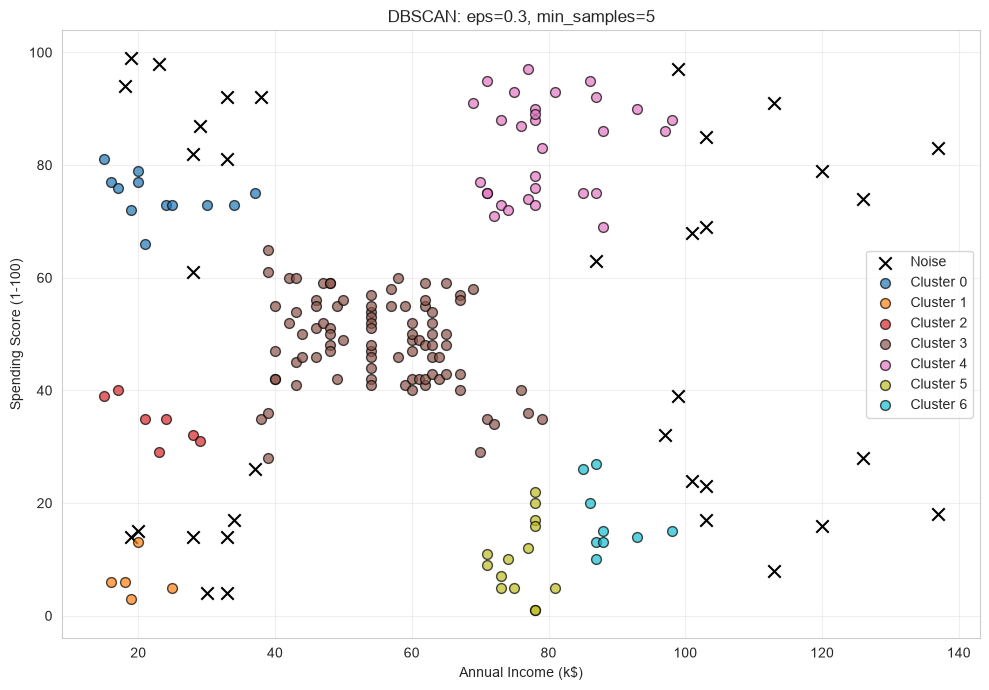

In [144]:
# Scatter plot hasil DBSCAN, pakai X asli (fitur asli) agar mudah diinterpretasi
plt.figure(figsize=(10, 7))

# Pisahkan noise dan cluster
noise_mask = labels_dbscan == -1

# Plot noise dulu (hitam, tanda x)
plt.scatter(
    X.loc[noise_mask, "Annual Income (k$)"],
    X.loc[noise_mask, "Spending Score (1-100)"],
    c="black", marker="x", s=80, label="Noise", edgecolors="k",
)

# Plot cluster
unique_labels = sorted(set(labels_dbscan) - {-1})
cmap = get_cmap("tab10", len(unique_labels))
for i, lab in enumerate(unique_labels):
    mask = labels_dbscan == lab
    plt.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        color=cmap(i), alpha=0.7, edgecolors="k", s=50,
        label=f"Cluster {lab}",
    )

plt.title("DBSCAN: eps=0.3, min_samples=5")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [145]:
# Coba beberapa kombinasi eps dan min_samples
eps_values = [0.2, 0.3, 0.4, 0.5, 0.6]
min_samples_values = [3, 5, 7, 10]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        lab = db.fit_predict(X_scaled)

        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int(np.sum(lab == -1))

        # Hitung silhouette hanya jika valid (>= 2 cluster dan tidak semua noise)
        sil = np.nan
        if n_clusters >= 2 and n_noise < len(lab):
            mask_valid = lab != -1
            if len(set(lab[mask_valid])) >= 2 and mask_valid.sum() > 1:
                sil = silhouette_score(X_scaled[mask_valid], lab[mask_valid])

        results.append({
            "eps": eps,
            "min_samples": min_samples,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "silhouette": sil,
        })

df_dbscan_results = pd.DataFrame(results)

# Rapikan tampilan
df_dbscan_results["silhouette"] = df_dbscan_results["silhouette"].round(4)

print("Ringkasan hasil tuning DBSCAN:")
display(df_dbscan_results.sort_values(
    by="silhouette", ascending=False, na_position="last"
).reset_index(drop=True))

Ringkasan hasil tuning DBSCAN:


,eps,min_samples,n_clusters,n_noise,silhouette
0,0.3,7,4,72,0.6452
1,0.2,7,4,100,0.6094
2,0.3,10,4,88,0.6073
3,0.4,10,4,51,0.5972
4,0.2,5,7,77,0.5856
5,0.3,5,7,35,0.5243
6,0.5,10,4,21,0.5107
7,0.4,7,4,20,0.4946
8,0.4,5,4,15,0.4781
9,0.3,3,9,14,0.4720


Kombinasi terbaik menurut silhouette:
eps             0.3000
min_samples     7.0000
n_clusters      4.0000
n_noise        72.0000
silhouette      0.6452
Name: 6, dtype: float64


C:\Users\airal\AppData\Local\Temp\ipykernel_38924\3116893427.py:15: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  plt.scatter(


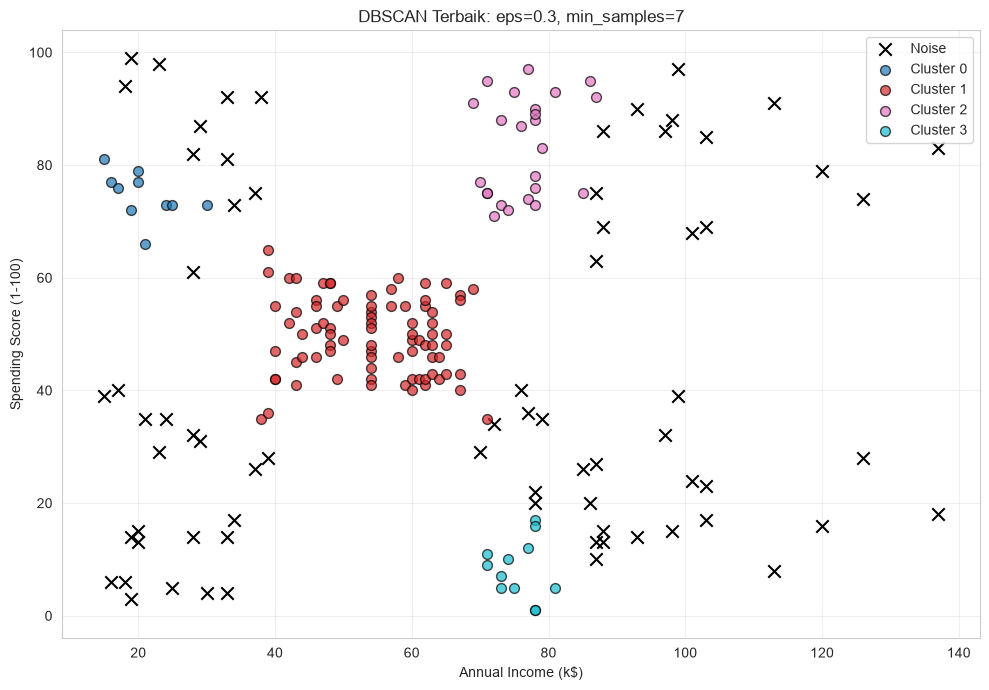

In [146]:
# Ambil kombinasi dengan silhouette tertinggi (abaikan NaN)
df_valid = df_dbscan_results.dropna(subset=["silhouette"])
best_row = df_valid.sort_values("silhouette", ascending=False).iloc[0]

print("Kombinasi terbaik menurut silhouette:")
print(best_row)

# Fit ulang dengan kombinasi terbaik
dbscan_best = DBSCAN(eps=best_row["eps"], min_samples=int(best_row["min_samples"]))
labels_dbscan_best = dbscan_best.fit_predict(X_scaled)

# Plot ulang
plt.figure(figsize=(10, 7))
noise_mask = labels_dbscan_best == -1
plt.scatter(
    X.loc[noise_mask, "Annual Income (k$)"],
    X.loc[noise_mask, "Spending Score (1-100)"],
    c="black", marker="x", s=80, label="Noise", edgecolors="k",
)
unique_labels = sorted(set(labels_dbscan_best) - {-1})
cmap = get_cmap("tab10", len(unique_labels))
for i, lab in enumerate(unique_labels):
    mask = labels_dbscan_best == lab
    plt.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        color=cmap(i), alpha=0.7, edgecolors="k", s=50,
        label=f"Cluster {lab}",
    )
plt.title(f"DBSCAN Terbaik: eps={best_row['eps']}, min_samples={int(best_row['min_samples'])}")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [164]:
# Cell diagnostik untuk analisis DBSCAN
print("Tabel tuning DBSCAN:")
display(df_dbscan_results)

print("\nKombinasi terbaik yang dipakai (labels_dbscan_best):")
print(f"eps         = {dbscan_best.eps}")
print(f"min_samples = {dbscan_best.min_samples}")

best_labels = labels_dbscan_best
n_clusters_best = len(set(best_labels)) - (1 if -1 in best_labels else 0)
n_noise_best = int(np.sum(best_labels == -1))
print(f"n_clusters  = {n_clusters_best}")
print(f"n_noise     = {n_noise_best}")

print("\nPengaruh eps (min_samples tetap):")
for ms in sorted(df_dbscan_results["min_samples"].unique()):
    sub = df_dbscan_results[df_dbscan_results["min_samples"] == ms].sort_values("eps")
    print(f"\nmin_samples = {ms}")
    print(sub[["eps", "n_clusters", "n_noise", "silhouette"]].to_string(index=False))

print("\nPengaruh min_samples (eps tetap):")
for eps in sorted(df_dbscan_results["eps"].unique()):
    sub = df_dbscan_results[df_dbscan_results["eps"] == eps].sort_values("min_samples")
    print(f"\neps = {eps}")
    print(sub[["min_samples", "n_clusters", "n_noise", "silhouette"]].to_string(index=False))

print("\nKombinasi degenerate:")
deg = df_dbscan_results[(df_dbscan_results["n_clusters"] <= 1) |
                        (df_dbscan_results["n_noise"] > len(X) * 0.3)]
print(deg[["eps", "min_samples", "n_clusters", "n_noise", "silhouette"]].to_string(index=False))

Tabel tuning DBSCAN:


,eps,min_samples,n_clusters,n_noise,silhouette
0,0.2,3,13,44,0.4697
1,0.2,5,7,77,0.5856
2,0.2,7,4,100,0.6094
3,0.2,10,1,129,NaN
4,0.3,3,9,14,0.4720
5,0.3,5,7,35,0.5243
6,0.3,7,4,72,0.6452
7,0.3,10,4,88,0.6073
8,0.4,3,4,10,0.3954
9,0.4,5,4,15,0.4781



Kombinasi terbaik yang dipakai (labels_dbscan_best):
eps         = 0.3
min_samples = 7
n_clusters  = 4
n_noise     = 72

Pengaruh eps (min_samples tetap):

min_samples = 3
 eps  n_clusters  n_noise  silhouette
 0.2          13       44      0.4697
 0.3           9       14      0.4720
 0.4           4       10      0.3954
 0.5           2        7      0.3892
 0.6           1        0         NaN

min_samples = 5
 eps  n_clusters  n_noise  silhouette
 0.2           7       77      0.5856
 0.3           7       35      0.5243
 0.4           4       15      0.4781
 0.5           2        8      0.3876
 0.6           1        5         NaN

min_samples = 7
 eps  n_clusters  n_noise  silhouette
 0.2           4      100      0.6094
 0.3           4       72      0.6452
 0.4           4       20      0.4946
 0.5           2       12      0.3942
 0.6           1        6         NaN

min_samples = 10
 eps  n_clusters  n_noise  silhouette
 0.2           1      129         NaN
 0.3           

### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?

    Jumlah cluster dan noise sama-sama turun. Contoh di min_samples=5: eps=0.2 → 7 cluster/77 noise, eps=0.4 → 4 cluster/15 noise, eps=0.6 → 1 cluster/5 noise. Naiknya eps bikin cluster menyatu.

- Apa pengaruh `min_samples`?

    Jumlah cluster cenderung turun dan noise naik. Contoh di eps=0.3: min_samples=3 → 9 cluster/14 noise, min_samples=7 → 4 cluster/72 noise. Terlalu besar bikin noise meledak; di eps=0.2, min_samples=10 malah jadi 1 cluster dengan 129 noise.

- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

    Satu cluster besar: semua eps=0.6 (silhouette NaN), dan eps=0.2, min_samples=10.

    Noise berlebihan (>30% data): eps=0.2 dengan min_samples 5/7/10, serta eps=0.3 dengan min_samples 7/10.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [147]:
# Latih BIRCH baseline
birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

# Jumlah anggota setiap cluster
print("Jumlah anggota setiap cluster BIRCH:")
print(pd.Series(labels_birch).value_counts().sort_index())

# Jumlah cluster
n_clusters_birch = len(set(labels_birch))
print(f"\nJumlah cluster yang terbentuk: {n_clusters_birch}")

Jumlah anggota setiap cluster BIRCH:
0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64

Jumlah cluster yang terbentuk: 5


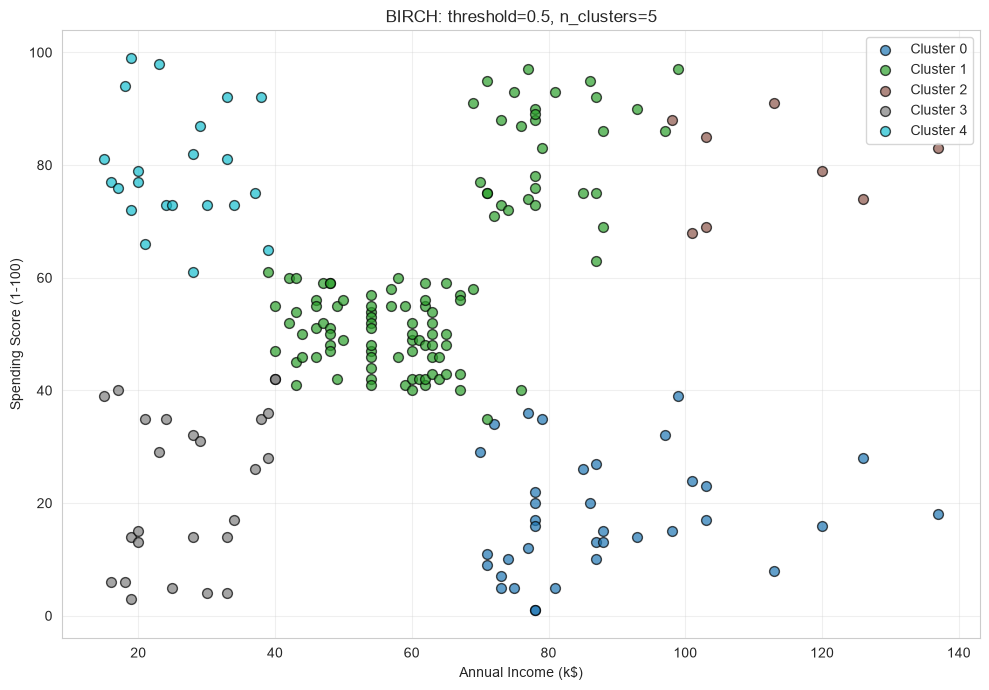

In [148]:
plt.figure(figsize=(10, 7))

unique_labels_birch = sorted(set(labels_birch))
cmap_birch = get_cmap("tab10", len(unique_labels_birch))

for i, lab in enumerate(unique_labels_birch):
    mask = labels_birch == lab
    plt.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        color=cmap_birch(i), alpha=0.7, edgecolors="k", s=50,
        label=f"Cluster {lab}",
    )

plt.title("BIRCH: threshold=0.5, n_clusters=5")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [149]:
# Bandingkan beberapa nilai threshold dengan n_clusters tetap = 5
threshold_values = [0.3, 0.5, 0.7, 1.0]
results_birch = []

for thr in threshold_values:
    birch_t = Birch(threshold=thr, n_clusters=5)
    lab_t = birch_t.fit_predict(X_scaled)

    n_clusters_t = len(set(lab_t))

    # Silhouette hanya valid jika >= 2 cluster
    sil = np.nan
    if n_clusters_t >= 2:
        sil = silhouette_score(X_scaled, lab_t)

    results_birch.append({
        "threshold": thr,
        "n_clusters": n_clusters_t,
        "silhouette": round(sil, 4) if not np.isnan(sil) else np.nan,
    })

df_birch_results = pd.DataFrame(results_birch)
print("Ringkasan tuning BIRCH (n_clusters target = 5):")
display(df_birch_results)

Ringkasan tuning BIRCH (n_clusters target = 5):


C:\Users\airal\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,threshold,n_clusters,silhouette
0,0.3,5,0.4781
1,0.5,5,0.4145
2,0.7,5,0.4207
3,1.0,4,0.3886


C:\Users\airal\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


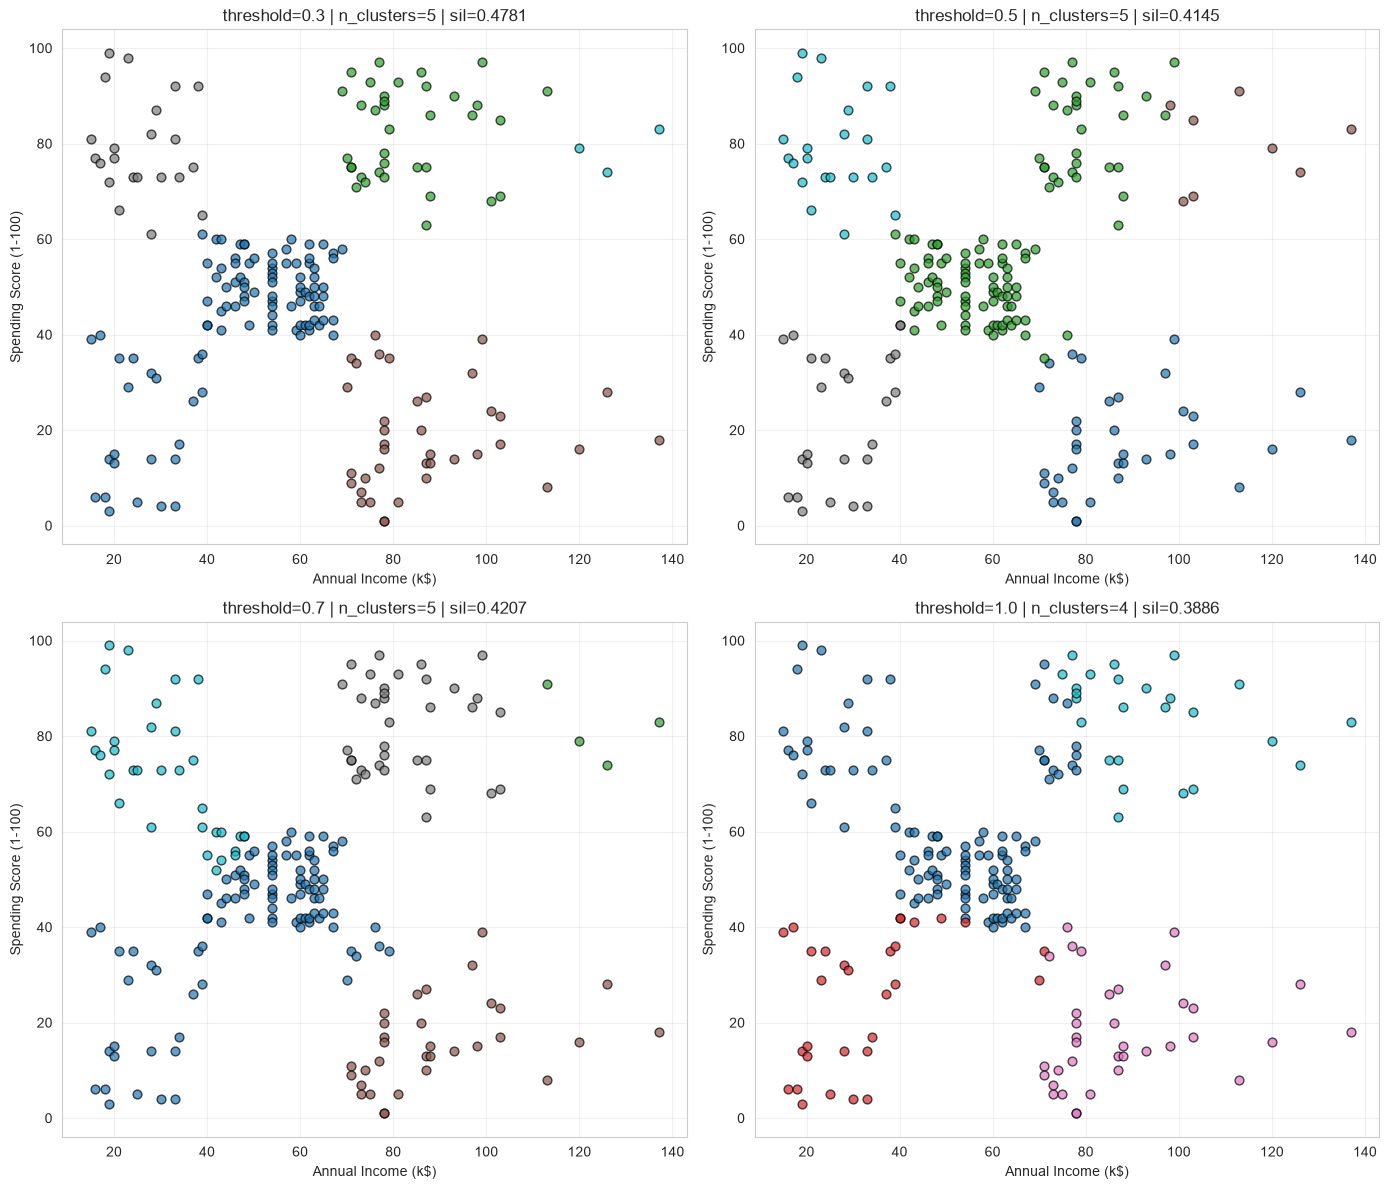

In [150]:
# Visualkan semua threshold dalam satu grid
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, thr in zip(axes, threshold_values):
    birch_t = Birch(threshold=thr, n_clusters=5)
    lab_t = birch_t.fit_predict(X_scaled)

    unique_labs = sorted(set(lab_t))
    cmap_t = get_cmap("tab10", len(unique_labs))

    for i, lab in enumerate(unique_labs):
        mask = lab_t == lab
        ax.scatter(
            X.loc[mask, "Annual Income (k$)"],
            X.loc[mask, "Spending Score (1-100)"],
            color=cmap_t(i), alpha=0.7, edgecolors="k", s=40,
        )

    sil_val = df_birch_results.loc[
        df_birch_results["threshold"] == thr, "silhouette"
    ].values[0]
    ax.set_title(f"threshold={thr} | n_clusters={len(unique_labs)} | sil={sil_val}")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [151]:
# Pilih threshold dengan silhouette tertinggi
df_valid_birch = df_birch_results.dropna(subset=["silhouette"])
best_birch_row = df_valid_birch.sort_values("silhouette", ascending=False).iloc[0]
best_thr = best_birch_row["threshold"]

print(f"Threshold terbaik menurut silhouette: {best_thr}")
print(best_birch_row)

# Fit ulang dengan threshold terbaik
birch_best = Birch(threshold=best_thr, n_clusters=5)
labels_birch_best = birch_best.fit_predict(X_scaled)

print("\nJumlah anggota setiap cluster (model terbaik):")
print(pd.Series(labels_birch_best).value_counts().sort_index())

Threshold terbaik menurut silhouette: 0.3
threshold     0.3000
n_clusters    5.0000
silhouette    0.4781
Name: 0, dtype: float64

Jumlah anggota setiap cluster (model terbaik):
0    101
1     36
2     38
3     22
4      3
Name: count, dtype: int64


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
    Dengan n_clusters=None, jumlah cluster turun seiring naiknya threshold: 0.3 → 23 cluster, 0.5 → 10, 0.7 → 6, 1.0 → 4. Threshold besar bikin subcluster menampung lebih banyak titik, pohon jadi lebih dangkal, jadi cluster akhir lebih sedikit dan lebih kasar.

    Dengan n_clusters=5 (dipaksa), hasilnya tetap 5 cluster untuk threshold 0.3–0.7, tapi di threshold 1.0 justru gagal capai 5: cuma terbentuk 4 cluster (ada ConvergenceWarning). Artinya threshold terlalu besar bisa bertabrakan dengan target n_clusters.

- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?

    DBSCAN menandai titik jauh sebagai noise (label -1), BIRCH tetap memasukkannya ke cluster terdekat. Contoh, empat titik income > 110:

    - index 196 (126, 28) → BIRCH cluster 2, DBSCAN noise

    - index 197 (126, 74) → BIRCH cluster 4, DBSCAN noise

    - index 198 (137, 18) → BIRCH cluster 2, DBSCAN noise

    - index 199 (137, 83) → BIRCH cluster 4, DBSCAN noise

    Semua titik ini dianggap outlier oleh DBSCAN, tapi diserap BIRCH ke cluster income menengah/tinggi. Konsekuensinya, cluster BIRCH bisa "tercemar" titik ekstrem, sementara DBSCAN bersih tapi kehilangan informasi.

- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

    Ya, sangat. Tanpa n_clusters, jumlah cluster sangat bergantung threshold (23, 10, 6, 4). Dengan n_clusters=5, hasil dipaksa jadi 5 cluster, tapi komposisinya berbeda per threshold. 

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [152]:
# Latih GMM baseline
gmm = GaussianMixture(
    n_components=5,
    covariance_type="full",
    random_state=42,
)
labels_gmm = gmm.fit_predict(X_scaled)

# Jumlah anggota setiap cluster
print("Jumlah anggota setiap cluster GMM:")
print(pd.Series(labels_gmm).value_counts().sort_index())

# Jumlah cluster yang terbentuk
print(f"\nJumlah cluster: {len(set(labels_gmm))}")

# Parameter model
print(f"\nConverged: {gmm.converged_}")
print(f"Jumlah iterasi EM: {gmm.n_iter_}")
print(f"BIC: {gmm.bic(X_scaled):.4f}")
print(f"AIC: {gmm.aic(X_scaled):.4f}")
print(f"Log-likelihood: {gmm.score(X_scaled) * len(X_scaled):.4f}")

Jumlah anggota setiap cluster GMM:
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64

Jumlah cluster: 5

Converged: True
Jumlah iterasi EM: 5
BIC: 1058.6523
AIC: 963.0010
Log-likelihood: -452.5005


In [153]:
# Probabilitas keanggotaan tiap titik
proba = gmm.predict_proba(X_scaled)

# DataFrame probabilitas untuk 10 titik pertama
df_proba = pd.DataFrame(
    proba,
    columns=[f"P(cluster {i})" for i in range(gmm.n_components)],
)

print("Probabilitas keanggotaan 10 titik pertama:")
display(df_proba.head(10).round(3))

# Max probability per titik: mengukur keyakinan model
max_proba = proba.max(axis=1)
print("\nStatistik max probability (keyakinan model):")
print(pd.Series(max_proba).describe().round(4))

# Titik yang relatif tidak pasti (max proba < 0.6)
ambiguous_thr = 0.6
n_ambiguous = int((max_proba < ambiguous_thr).sum())
print(f"\nJumlah titik dengan max proba < {ambiguous_thr}: {n_ambiguous}")
print(f"Persentase: {n_ambiguous / len(max_proba) * 100:.2f}%")

# Tampilkan beberapa titik paling ambigu
df_ambiguous = X.copy()
df_ambiguous["cluster"] = labels_gmm
df_ambiguous["max_proba"] = max_proba
print("\n5 titik paling ambigu:")
display(
    df_ambiguous.sort_values("max_proba").head(5).round(3)
)

Probabilitas keanggotaan 10 titik pertama:


,P(cluster 0),P(cluster 1),P(cluster 2),P(cluster 3),P(cluster 4)
0,0.000,0.0,0.001,0.0,0.999
1,0.000,0.0,1.000,0.0,0.000
2,0.000,0.0,0.000,0.0,1.000
3,0.000,0.0,1.000,0.0,0.000
4,0.000,0.0,0.002,0.0,0.998
5,0.000,0.0,1.000,0.0,0.000
6,0.000,0.0,0.000,0.0,1.000
7,0.000,0.0,1.000,0.0,0.000
8,0.000,0.0,0.000,0.0,1.000
9,0.001,0.0,0.998,0.0,0.000



Statistik max probability (keyakinan model):
count    200.0000
mean       0.9827
std        0.0627
min        0.5029
25%        0.9961
50%        0.9996
75%        1.0000
max        1.0000
dtype: float64

Jumlah titik dengan max proba < 0.6: 1
Persentase: 0.50%

5 titik paling ambigu:


,Annual Income (k$),Spending Score (1-100),cluster,max_proba
124,70,29,3,0.503
48,40,42,0,0.611
49,40,42,0,0.611
27,28,61,2,0.675
160,79,35,0,0.772


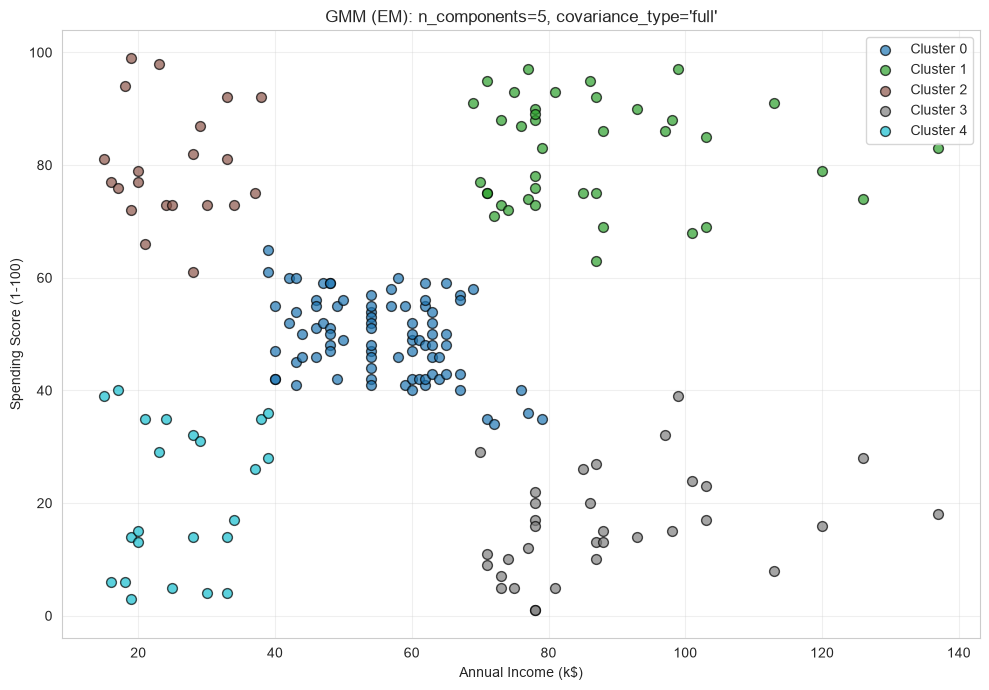

In [154]:
plt.figure(figsize=(10, 7))

unique_labels_gmm = sorted(set(labels_gmm))
cmap_gmm = get_cmap("tab10", len(unique_labels_gmm))

for i, lab in enumerate(unique_labels_gmm):
    mask = labels_gmm == lab
    plt.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        color=cmap_gmm(i), alpha=0.7, edgecolors="k", s=50,
        label=f"Cluster {lab}",
    )

plt.title("GMM (EM): n_components=5, covariance_type='full'")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [155]:
# Bandingkan beberapa nilai n_components
n_components_values = list(range(2, 9))
results_gmm = []

for k in n_components_values:
    gmm_k = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=42,
        n_init=5,
    )
    lab_k = gmm_k.fit_predict(X_scaled)

    n_clusters_k = len(set(lab_k))

    sil = np.nan
    if n_clusters_k >= 2:
        sil = silhouette_score(X_scaled, lab_k)

    results_gmm.append({
        "n_components": k,
        "n_clusters_actual": n_clusters_k,
        "silhouette": round(sil, 4) if not np.isnan(sil) else np.nan,
        "BIC": round(gmm_k.bic(X_scaled), 2),
        "AIC": round(gmm_k.aic(X_scaled), 2),
        "converged": gmm_k.converged_,
    })

df_gmm_results = pd.DataFrame(results_gmm)
print("Ringkasan tuning GMM:")
display(df_gmm_results)

Ringkasan tuning GMM:


,n_components,n_clusters_actual,silhouette,BIC,AIC,converged
0,2,2,0.3872,1148.47,1112.19,True
1,3,3,0.4302,1151.72,1095.65,True
2,4,4,0.4509,1079.49,1003.63,True
3,5,5,0.5537,1058.65,963.00,True
4,6,6,0.5358,1071.57,956.13,True
5,7,7,0.3852,1085.59,950.36,True
6,8,8,0.4651,1082.48,927.46,True


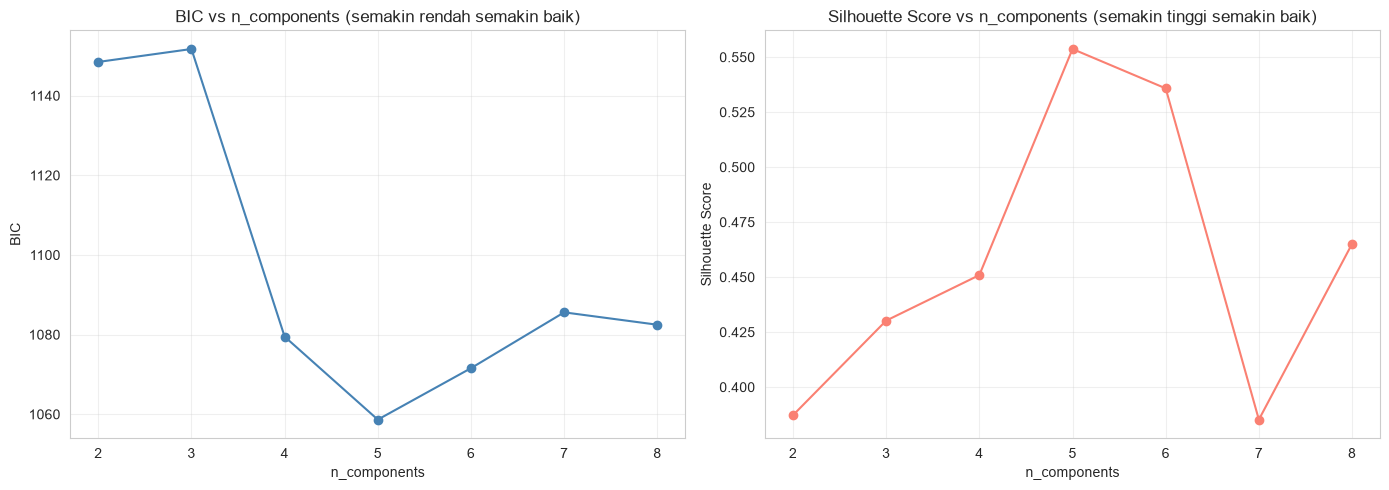

In [156]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# BIC
axes[0].plot(
    df_gmm_results["n_components"],
    df_gmm_results["BIC"],
    marker="o", color="steelblue",
)
axes[0].set_title("BIC vs n_components (semakin rendah semakin baik)")
axes[0].set_xlabel("n_components")
axes[0].set_ylabel("BIC")
axes[0].grid(True, alpha=0.3)

# Silhouette
axes[1].plot(
    df_gmm_results["n_components"],
    df_gmm_results["silhouette"],
    marker="o", color="salmon",
)
axes[1].set_title("Silhouette Score vs n_components (semakin tinggi semakin baik)")
axes[1].set_xlabel("n_components")
axes[1].set_ylabel("Silhouette Score")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

n_components dengan BIC terendah: 5
n_components               5
n_clusters_actual          5
silhouette            0.5537
BIC                  1058.65
AIC                    963.0
converged               True
Name: 3, dtype: object

Jumlah anggota setiap cluster (model terbaik):
0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64


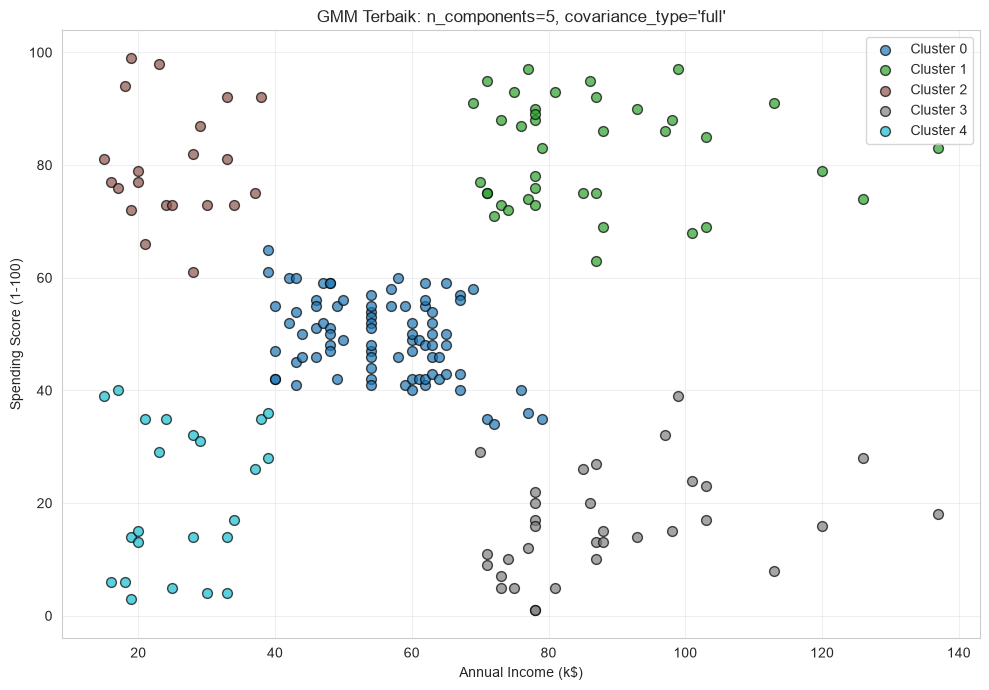

In [157]:
# Pilih model dengan BIC terendah sebagai acuan utama,
# bandingkan dengan silhouette di tabel.
best_bic_row = df_gmm_results.sort_values("BIC").iloc[0]
best_k_bic = int(best_bic_row["n_components"])

print(f"n_components dengan BIC terendah: {best_k_bic}")
print(best_bic_row)

# Fit ulang dengan n_components terbaik
gmm_best = GaussianMixture(
    n_components=best_k_bic,
    covariance_type="full",
    random_state=42,
    n_init=5,
)
labels_gmm_best = gmm_best.fit_predict(X_scaled)

print("\nJumlah anggota setiap cluster (model terbaik):")
print(pd.Series(labels_gmm_best).value_counts().sort_index())

# Plot final
plt.figure(figsize=(10, 7))
unique_labels_best = sorted(set(labels_gmm_best))
cmap_best = get_cmap("tab10", len(unique_labels_best))

for i, lab in enumerate(unique_labels_best):
    mask = labels_gmm_best == lab
    plt.scatter(
        X.loc[mask, "Annual Income (k$)"],
        X.loc[mask, "Spending Score (1-100)"],
        color=cmap_best(i), alpha=0.7, edgecolors="k", s=50,
        label=f"Cluster {lab}",
    )

plt.title(f"GMM Terbaik: n_components={best_k_bic}, covariance_type='full'")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
    predict_proba memberi seberapa yakin tiap titik milik setiap komponen Gaussian, dengan total per titik = 1. Di model terbaik (n_components=5), distribusi keyakinannya sangat tinggi: rata-rata max probability 0.9827, median 0.9996. Hanya 1 titik (<0.5%) dengan keyakinan di bawah 0.6, dan 8 titik (4%) di bawah 0.9. Jadi mayoritas titik sangat jelas clusternya, hanya segelintir berada di batas antar komponen.

- Apa yang terjadi ketika `n_components` diubah?
    Jumlah cluster aktual selalu sama dengan n_components (GMM tidak bisa punya komponen kosong). Perubahan yang terjadi ada di kualitas:

    - Silhouette naik dari 2 (0.3872) ke 5 (0.5537), lalu turun di 7 (0.3852) dan naik lagi sedikit di 8 (0.4651). Pola tidak monoton.

    - BIC turun dari 2 (1148.47) sampai minimum di 5 (1058.65), lalu naik lagi di 6 (1071.57) dan seterusnya.

    - AIC terus turun sampai 8 (927.46) karena AIC memberi penalti lebih ringan pada kompleksitas, jadi cenderung memilih model lebih besar.

- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
    Karena GMM bukan algoritma yang "menemukan" jumlah cluster sendiri. EM mengestimasi parameter (mean, covariance, bobot) untuk sejumlah komponen yang sudah ditetapkan di awal. Kalau n_components tidak ditentukan, GMM tidak punya target berapa komponen yang harus di-fit.

- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?
    ya. Keduanya jatuh di n_components=5:

    - Silhouette tertinggi: 0.5537 di k=5

    - BIC terendah: 1058.65 di k=5

    - Silhouette tertinggi == BIC terendah? True

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [161]:
def evaluate_clustering(X_scaled, labels, model_name, treat_noise=True):
    """
    Evaluasi hasil clustering.

    Parameters
    ----------
    X_scaled : array-like atau DataFrame
        Data ter-standardisasi.
    labels : array-like
        Label cluster hasil model. Noise ditandai -1 (khusus DBSCAN).
    model_name : str
        Nama model untuk pelaporan.
    treat_noise : bool
        Jika True, label -1 dianggap noise dan dikeluarkan dari evaluasi.

    Returns
    -------
    dict berisi metrik dan status validitas.
    """
    labels = np.asarray(labels)
    X_arr = np.asarray(X_scaled)

    if treat_noise:
        mask_valid = labels != -1
    else:
        mask_valid = np.ones(len(labels), dtype=bool)

    X_eval = X_arr[mask_valid]
    labels_eval = labels[mask_valid]

    n_noise = int(np.sum(labels == -1)) if treat_noise else 0
    n_clusters = len(set(labels_eval))

    result = {
        "model": model_name,
        "n_clusters": n_clusters,
        "n_noise": n_noise,
        "n_points_evaluated": len(labels_eval),
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "calinski_harabasz": np.nan,
        "valid": False,
        "reason": "",
    }

    # Validitas: minimal 2 cluster dan jumlah cluster < jumlah titik
    if n_clusters < 2:
        result["reason"] = "kurang dari 2 cluster"
        return result
    if n_clusters >= len(labels_eval):
        result["reason"] = "jumlah cluster >= jumlah titik"
        return result

    result["silhouette"] = round(silhouette_score(X_eval, labels_eval), 4)
    result["davies_bouldin"] = round(davies_bouldin_score(X_eval, labels_eval), 4)
    result["calinski_harabasz"] = round(calinski_harabasz_score(X_eval, labels_eval), 2)
    result["valid"] = True
    result["reason"] = "ok"
    return result

In [159]:
# Evaluasi model terbaik dari tiap algoritma
eval_dbscan = evaluate_clustering(
    X_scaled, labels_dbscan_best, "DBSCAN", treat_noise=True
)
eval_birch = evaluate_clustering(
    X_scaled, labels_birch_best, "BIRCH", treat_noise=False
)
eval_gmm = evaluate_clustering(
    X_scaled, labels_gmm_best, "GMM", treat_noise=False
)

df_eval = pd.DataFrame([eval_dbscan, eval_birch, eval_gmm])

# Tampilkan tanpa kolom bantu
cols_show = [
    "model", "n_clusters", "n_noise",
    "silhouette", "davies_bouldin", "calinski_harabasz", "valid",
]
print("Ringkasan Evaluasi Model Terbaik")
display(df_eval[cols_show])

Ringkasan Evaluasi Model Terbaik


,model,n_clusters,n_noise,silhouette,davies_bouldin,calinski_harabasz,valid
0,DBSCAN,4,72,0.6452,0.4190,244.91,True
1,BIRCH,5,0,0.4781,0.6477,144.01,True
2,GMM,5,0,0.5537,0.5760,244.94,True


C:\Users\airal\AppData\Local\Temp\ipykernel_38924\3265274787.py:16: UserWarning: You passed an edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(


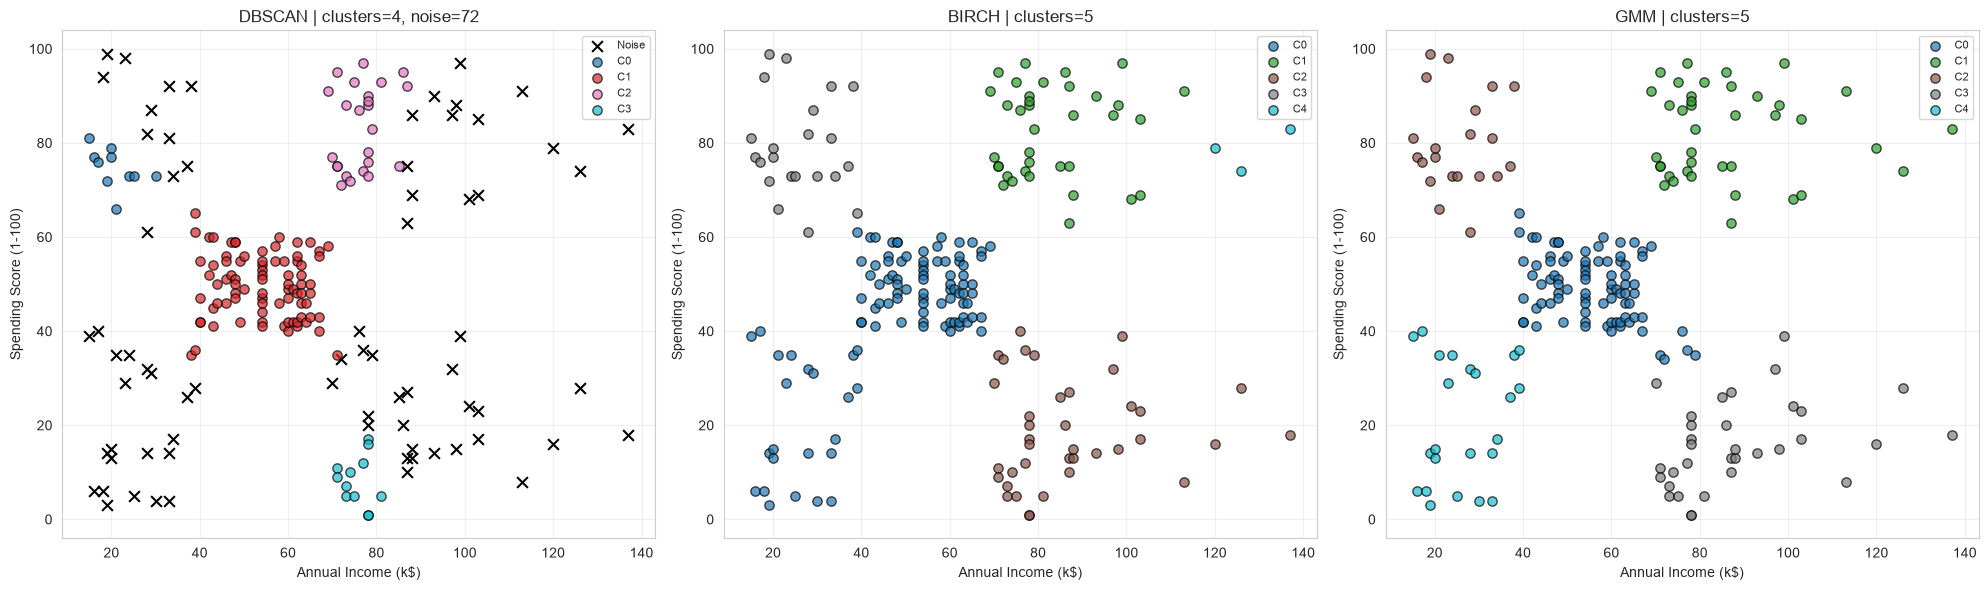

In [162]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

models_to_plot = [
    ("DBSCAN", labels_dbscan_best, eval_dbscan),
    ("BIRCH", labels_birch_best, eval_birch),
    ("GMM", labels_gmm_best, eval_gmm),
]

for ax, (name, labels, ev) in zip(axes, models_to_plot):
    labels = np.asarray(labels)
    unique_labs = sorted(set(labels))

    # Noise dulu (DBSCAN saja)
    if -1 in unique_labs:
        mask_noise = labels == -1
        ax.scatter(
            X.loc[mask_noise, "Annual Income (k$)"],
            X.loc[mask_noise, "Spending Score (1-100)"],
            c="black", marker="x", s=60, label="Noise", edgecolors="k",
        )
        unique_labs = [l for l in unique_labs if l != -1]

    cmap = get_cmap("tab10", max(len(unique_labs), 1))
    for i, lab in enumerate(unique_labs):
        mask = labels == lab
        ax.scatter(
            X.loc[mask, "Annual Income (k$)"],
            X.loc[mask, "Spending Score (1-100)"],
            color=cmap(i), alpha=0.7, edgecolors="k", s=45,
            label=f"C{lab}",
        )

    n_c = ev["n_clusters"]
    n_n = ev["n_noise"]
    title = f"{name} | clusters={n_c}"
    if n_n > 0:
        title += f", noise={n_n}"
    ax.set_title(title)
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")
    ax.legend(fontsize=8, loc="best")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [163]:
def cluster_profile(X_original, labels, model_name, is_dbscan=False):
    """
    Tampilkan profil cluster (ukuran, mean, median) di fitur asli.
    Untuk DBSCAN, pisahkan noise sebagai baris sendiri.
    """
    labels = np.asarray(labels)
    df_tmp = X_original.copy().reset_index(drop=True)
    df_tmp["cluster"] = labels

    rows = []
    for lab in sorted(set(labels)):
        mask = df_tmp["cluster"] == lab
        subset = df_tmp[mask]
        label_name = "NOISE (-1)" if (is_dbscan and lab == -1) else f"Cluster {lab}"
        rows.append({
            "model": model_name,
            "cluster": label_name,
            "n": int(mask.sum()),
            "income_mean": round(subset["Annual Income (k$)"].mean(), 2),
            "income_median": round(subset["Annual Income (k$)"].median(), 2),
            "score_mean": round(subset["Spending Score (1-100)"].mean(), 2),
            "score_median": round(subset["Spending Score (1-100)"].median(), 2),
        })
    return pd.DataFrame(rows)


profile_dbscan = cluster_profile(X, labels_dbscan_best, "DBSCAN", is_dbscan=True)
profile_birch = cluster_profile(X, labels_birch_best, "BIRCH", is_dbscan=False)
profile_gmm = cluster_profile(X, labels_gmm_best, "GMM", is_dbscan=False)

print("Profil Cluster DBSCAN")
display(profile_dbscan)

print("Profil Cluster BIRCH")
display(profile_birch)

print("Profil Cluster GMM")
display(profile_gmm)

# Gabungan opsional
profile_all = pd.concat(
    [profile_dbscan, profile_birch, profile_gmm], ignore_index=True
)
print("Gabungan Profil Cluster")
display(profile_all)

Profil Cluster DBSCAN


,model,cluster,n,income_mean,income_median,score_mean,score_median
0,DBSCAN,NOISE (-1),72,65.50,77.5,43.35,32.0
1,DBSCAN,Cluster 0,10,20.70,20.0,74.70,74.5
2,DBSCAN,Cluster 1,82,54.23,54.0,49.67,50.0
3,DBSCAN,Cluster 2,24,76.46,77.0,83.33,85.0
4,DBSCAN,Cluster 3,12,75.58,76.0,8.25,8.0


Profil Cluster BIRCH


,model,cluster,n,income_mean,income_median,score_mean,score_median
0,BIRCH,Cluster 0,101,48.17,50.0,43.40,47.0
1,BIRCH,Cluster 1,36,83.11,78.0,82.42,85.5
2,BIRCH,Cluster 2,38,87.00,80.0,18.63,16.5
3,BIRCH,Cluster 3,22,25.73,24.5,79.36,77.0
4,BIRCH,Cluster 4,3,127.67,126.0,78.67,79.0


Profil Cluster GMM


,model,cluster,n,income_mean,income_median,score_mean,score_median
0,GMM,Cluster 0,84,55.64,55.5,49.37,49.5
1,GMM,Cluster 1,39,86.54,79.0,82.13,83.0
2,GMM,Cluster 2,21,25.10,24.0,80.05,77.0
3,GMM,Cluster 3,33,88.82,86.0,16.00,15.0
4,GMM,Cluster 4,23,26.30,25.0,20.91,17.0


Gabungan Profil Cluster


,model,cluster,n,income_mean,income_median,score_mean,score_median
0,DBSCAN,NOISE (-1),72,65.50,77.5,43.35,32.0
1,DBSCAN,Cluster 0,10,20.70,20.0,74.70,74.5
2,DBSCAN,Cluster 1,82,54.23,54.0,49.67,50.0
3,DBSCAN,Cluster 2,24,76.46,77.0,83.33,85.0
4,DBSCAN,Cluster 3,12,75.58,76.0,8.25,8.0
5,BIRCH,Cluster 0,101,48.17,50.0,43.40,47.0
6,BIRCH,Cluster 1,36,83.11,78.0,82.42,85.5
7,BIRCH,Cluster 2,38,87.00,80.0,18.63,16.5
8,BIRCH,Cluster 3,22,25.73,24.5,79.36,77.0
9,BIRCH,Cluster 4,3,127.67,126.0,78.67,79.0


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak. Jumlah cluster muncul dari kepadatan; parameter yang diatur `eps` dan `min_samples` | Opsional. Bisa `n_clusters=None` atau dipaksa eksplisit | Ya. `n_components` wajib ditentukan sebelum latih |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 | Tidak, semua titik masuk cluster | Tidak, semua titik dapat probabilitas keanggotaan |
| Parameter paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` dan `n_clusters` | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Arbitrer, mengikuti kontur kepadatan, bisa non-convex | Cenderung spherical/ellipsoidal karena subcluster diringkas statistik linear | Ellipsoidal fleksibel, tiap komponen bisa beda orientasi dan ukuran jika `full` |
| Kelebihan | Deteksi noise, tidak perlu tahu jumlah cluster, tahan outlier | Cepat, hemat memori, deterministik, cocok data besar | Probabilitas keanggotaan, fleksibel bentuk, ada kriteria model (BIC/AIC) |
| Kekurangan | Sensitif ke `eps` dan `min_samples`, sulit untuk kepadatan bervariasi | Tidak ada noise, perlu tuning threshold, hasil berubah jika `n_clusters` dipaksa | Harus tentukan `n_components`, asumsi Gaussian, berisiko overfit di data kecil |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?

    Kedua fitur punya skala berbeda: Annual Income 15–137 sedangkan Spending Score 1–99. DBSCAN dan BIRCH memakai jarak Euclidean, GMM memakai kovarians. Tanpa scaling, fitur dengan rentang lebih besar mendominasi perhitungan dan membuat kontribusi kedua fitur tidak seimbang. Setelah StandardScaler, rata-rata tiap fitur menjadi 0 dan standar deviasi 1, sehingga keduanya setara. Parameter eps juga jadi lebih mudah diinterpretasikan karena satuannya dalam satuan standar deviasi.

2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?

    Dari tabel tuning, kenaikan eps menurunkan jumlah cluster dan noise. Contoh di min_samples=5: eps=0.2 menghasilkan 7 cluster dan 77 noise, sedangkan eps=0.6 menyisakan 1 cluster. Kenaikan min_samples juga menurunkan jumlah cluster tetapi menambah noise. Contoh di eps=0.3: min_samples=3 memberi 9 cluster dan 14 noise, sedangkan min_samples=7 memberi 4 cluster dan 72 noise. Kombinasi degenerat juga muncul: semua eps=0.6 menghasilkan satu cluster besar (silhouette NaN), dan eps=0.2 dengan min_samples 7–10 membuang 100–129 titik sebagai noise.

3. Bagaimana parameter threshold dan n_clusters memengaruhi BIRCH?

    Dengan n_clusters=None, kenaikan threshold menurunkan jumlah cluster secara tajam: 0.3 menghasilkan 23 cluster, 0.5 menghasilkan 10, 0.7 menghasilkan 6, dan 1.0 menghasilkan 4. Dengan n_clusters=5, jumlah cluster dipaksa lima, tetapi komposisi ukurannya berbeda per threshold. Pada threshold 1.0 bahkan gagal mencapai lima karena CF-tree hanya terbentuk empat subcluster (ConvergenceWarning). Cluster kecil berisi 3–8 titik muncul konsisten dan cenderung menampung titik-titik yang sebenarnya menyendiri.

4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?

    predict_proba menyatakan seberapa yakin tiap titik milik setiap komponen Gaussian, dengan total per titik sama dengan 1. Pada model terbaik, rata-rata max probability 0.9827 dan median 0.9996, artinya mayoritas titik sangat yakin. Hanya satu titik (0.5%) dengan keyakinan di bawah 0.6, misalnya titik income 70 dan score 29 dengan probabilitas 0.503 di cluster 3. EM bekerja bergantian: E-step menghitung probabilitas keanggotaan berdasarkan parameter saat ini, M-step memperbarui mean, covariance, dan bobot untuk memaksimalkan likelihood. Iterasi berhenti saat konvergen, pada model ini setelah 5 iterasi.

5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.

    GMM paling mudah diinterpretasikan. Alasannya: semua 200 titik mendapat segmen, tiap titik punya probabilitas keanggotaan sehingga tingkat ketidakpastian bisa dibaca, jumlah cluster lima sesuai pola visual scatter plot, dan lima kelompok itu punya profil pendapatan serta spending yang jelas. DBSCAN memang memberi segmen tegas, tetapi membuang 72 pelanggan sebagai noise sehingga sulit dipakai untuk segmentasi menyeluruh. BIRCH juga mudah karena semua titik terpakai, tetapi cluster mungil berisi tiga titik membuat interpretasi bisnis jadi kurang rapi.

6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?

    Ya, DBSCAN unggul di semua metrik: silhouette 0.6452, Davies-Bouldin 0.4190, Calinski-Harabasz 244.91. GMM di urutan kedua dengan silhouette 0.5537, sedangkan BIRCH paling rendah dengan 0.4781. Namun keunggulan DBSCAN tidak sepenuhnya sebanding karena metriknya hanya dihitung pada 128 dari 200 titik, sementara BIRCH dan GMM dievaluasi pada seluruh 200 titik. Kalau noise ikut diperhitungkan sebagai pelanggan tanpa segmen, DBSCAN justru kehilangan 36% data. Penyebab perbedaan interpretasi ini adalah basis evaluasi yang tidak sama, bukan semata kualitas cluster.

7. Karakteristik cluster berdasarkan median pendapatan dan spending score

    Berdasarkan profil cluster GMM dan BIRCH yang terbentuk dari lima segmen, pola karakteristiknya sebagai berikut. Segmen hemat berdaya beli rendah punya median income rendah sekitar 25 dan median spending rendah sekitar 20, cenderung menahan diri. Segmen impulsif berdaya beli rendah punya median income rendah sekitar 25 tetapi spending tinggi sekitar 80, pola konsumtif. Segmen pelanggan standar punya median income menengah sekitar 55 dan spending menengah sekitar 50, dan jumlahnya paling besar. Segmen hemat berdaya beli tinggi punya income tinggi sekitar 85 tetapi spending rendah sekitar 20, potensi retensi. Segmen premium punya income tinggi sekitar 85 dan spending tinggi sekitar 80, target kampanye eksklusif. Cluster mungil berisi tiga titik di BIRCH dan empat titik ekstrem di DBSCAN (income di atas 110) cocok disebut pelanggan langka atau outlier, perlu dicek manual apakah memang segmen bermakna atau hanya data ekstrem.

8. Keterbatasan penggunaan hanya dua fitur dan dataset kecil

    Dua fitur hanya menangkap daya beli dan intensitas belanja. Faktor lain seperti usia, gender, frekuensi kunjungan, kategori produk, dan riwayat transaksi tidak masuk model, sehingga segmen bisa jadi terlalu kasar. Dataset 200 baris membuat model rawan overfit, terutama GMM dengan covariance_type='full' yang mengestimasi banyak parameter per komponen. Hasil tuning parameter sangat sensitif, dan satu titik ekstrem bisa menggeser centroid. Karena data kecil, perbedaan metrik antar model mudah berubah hanya karena satu-dua titik. Klaim model terbaik sebaiknya divalidasi dengan data tambahan atau cross-validation sebelum dipakai untuk keputusan bisnis. Visualisasi 2D memang memudahkan interpretasi, tetapi menyembunyikan struktur yang mungkin muncul jika fitur ditambah.



# 8. Kesimpulan dan Saran

Algoritma yang paling berguna untuk dataset ini adalah GMM. DBSCAN sebenarnya punya metrik tertinggi (silhouette 0.6452), tetapi hanya dievaluasi pada 128 dari 200 titik karena 72 pelanggan dibuang sebagai noise. Untuk segmentasi pelanggan, membuang 36% data terlalu mahal. GMM memberi 5 cluster dengan silhouette 0.5537 pada seluruh 200 titik, BIC terendah di n_components=5 (1058.65), dan semua titik punya probabilitas keanggotaan. BIRCH paling lemah secara metrik (silhouette 0.4781) dan masih menyisakan cluster mungil berisi 3 titik.

**Parameter yang dipilih dan alasannya:**

- DBSCAN: eps=0.3, min_samples=7. Ini yang memberi silhouette tertinggi di tabel tuning, tetapi noise 72 titik jadi catatan penting. Alternatif yang lebih seimbang sebenarnya eps=0.4, min_samples=5 dengan noise hanya 15 titik meski silhouette 0.4781.

- BIRCH: threshold=0.3, n_clusters=5. Threshold ini memberi silhouette tertinggi di antara nilai yang dicoba (0.4781 vs 0.4145 di threshold 0.5), dan n_clusters=5 dipilih karena cocok dengan pola alami data.

- GMM: n_components=5, covariance_type='full'. Di sini silhouette tertinggi dan BIC terendah bertemu di angka yang sama, jadi pilihan ini didukung dua kriteria sekaligus. Konvergen dalam 5 iterasi dengan BIC 1058.65.

**Perbedaan utama ketiga algoritma:**

DBSCAN membentuk cluster dari kepadatan dan bisa menandai noise (label -1), sehingga parameter eps dan min_samples sangat menentukan hasil. BIRCH meringkas data ke CF-tree lalu menggabungkan subcluster, tidak punya konsep noise, dan hasilnya sangat bergantung pada threshold serta n_clusters. GMM memodelkan data sebagai campuran Gaussian dan dilatih dengan EM, menghasilkan probabilitas keanggotaan per titik serta kriteria pemilihan model lewat BIC/AIC, tetapi jumlah komponen harus ditentukan di awal. Ringkasnya, DBSCAN berbasis kepadatan dan bisa membuang titik, BIRCH berbasis hierarki ringkasan dan deterministik, GMM berbasis probabilitas dan fleksibel dalam bentuk cluster.

**Eksperimen lanjutan yang bisa dilakukan:**

- Menambah fitur seperti Age, Gender (di-encode), dan fitur turunan seperti rasio spending terhadap income, lalu bandingkan apakah cluster jadi lebih kaya makna.

- Melakukan cross-validation atau bootstrap pada dataset kecil ini untuk menguji stabilitas parameter terbaik, terutama karena satu-dua titik ekstrem bisa menggeser hasil DBSCAN dan GMM.

- Mencoba covariance_type lain di GMM ('tied', 'diag', 'spherical') dan membandingkan BIC untuk melihat apakah model yang lebih sederhana cukup.

- Menerapkan reduksi dimensi (PCA) atau UMAP sebelum clustering untuk melihat apakah struktur cluster tetap konsisten.

- Memakai K-Means sebagai baseline pembanding untuk melihat seberapa besar keunggulan metode yang lebih kompleks di dataset ini.

- Melakukan validasi eksternal, misalnya membandingkan segmen dengan data transaksi nyata, untuk memastikan cluster yang terbentuk benar-benar bermakna secara bisnis.

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)